## M1 Final Comparisons

### 1. Dependencies

In [1]:
from prep import *

### 2. Models 1-6 Weeks

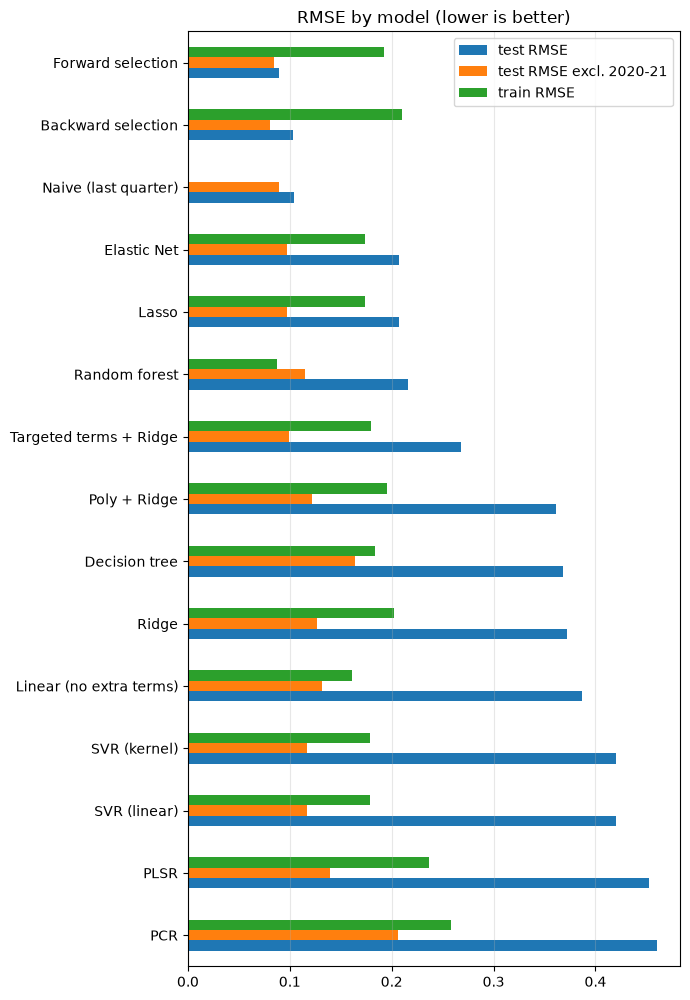

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),CV score,CV metric,best params,saved,Accuracy (vs threshold),test ROC_AUC
Forward selection,regressor,0.089,0.065,0.878,0.659,0.084,0.192,-0.103,0.22666,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17,NaN,NaN
Backward selection,regressor,0.103,0.063,0.836,0.636,0.081,0.21,-0.107,0.235818,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17,NaN,NaN
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Elastic Net,regressor,0.207,0.114,0.34,0.636,0.097,0.174,0.033,0.336756,root_mean_squared_error,"{'elasticnet__alpha': 0.019573417814876617, 'e...",2026-10-18 02:11,NaN,NaN
Lasso,regressor,0.207,0.114,0.339,0.636,0.097,0.174,0.033,0.336352,root_mean_squared_error,{'lasso__alpha': 0.020309176209047347},2026-10-18 02:06,NaN,NaN
Random forest,regressor,0.216,0.125,0.278,0.545,0.115,0.087,0.129,0.462389,root_mean_squared_error,"{'randomforestregressor__n_estimators': 200, '...",2026-10-18 05:12,NaN,NaN
Targeted terms + Ridge,regressor,0.268,0.139,-0.109,0.614,0.099,0.18,0.088,0.353107,root_mean_squared_error,"{'addterms__pairs': (('dq_other_cons_L1', 'une...",2026-10-18 01:43,NaN,NaN
Poly + Ridge,regressor,0.361,0.157,-1.014,0.636,0.122,0.195,0.166,0.38412,root_mean_squared_error,"{'polynomialfeatures__degree': 1, 'polynomialf...",2026-10-18 01:10,NaN,NaN
Decision tree,regressor,0.368,0.178,-1.094,0.5,0.164,0.184,0.184,0.464789,root_mean_squared_error,"{'decisiontreeregressor__max_depth': 4, 'decis...",2026-10-18 05:06,NaN,NaN
Ridge,regressor,0.372,0.169,-1.138,0.614,0.127,0.202,0.17,0.384148,root_mean_squared_error,{'ridge__alpha': 32.57020655659783},2026-10-18 02:00,NaN,NaN


In [3]:
final = compare()           # regression models + naive, sorted by test RMSE
final

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)
threshold = 1.050 (training 50% quantile); share above: train 50%, test 20%


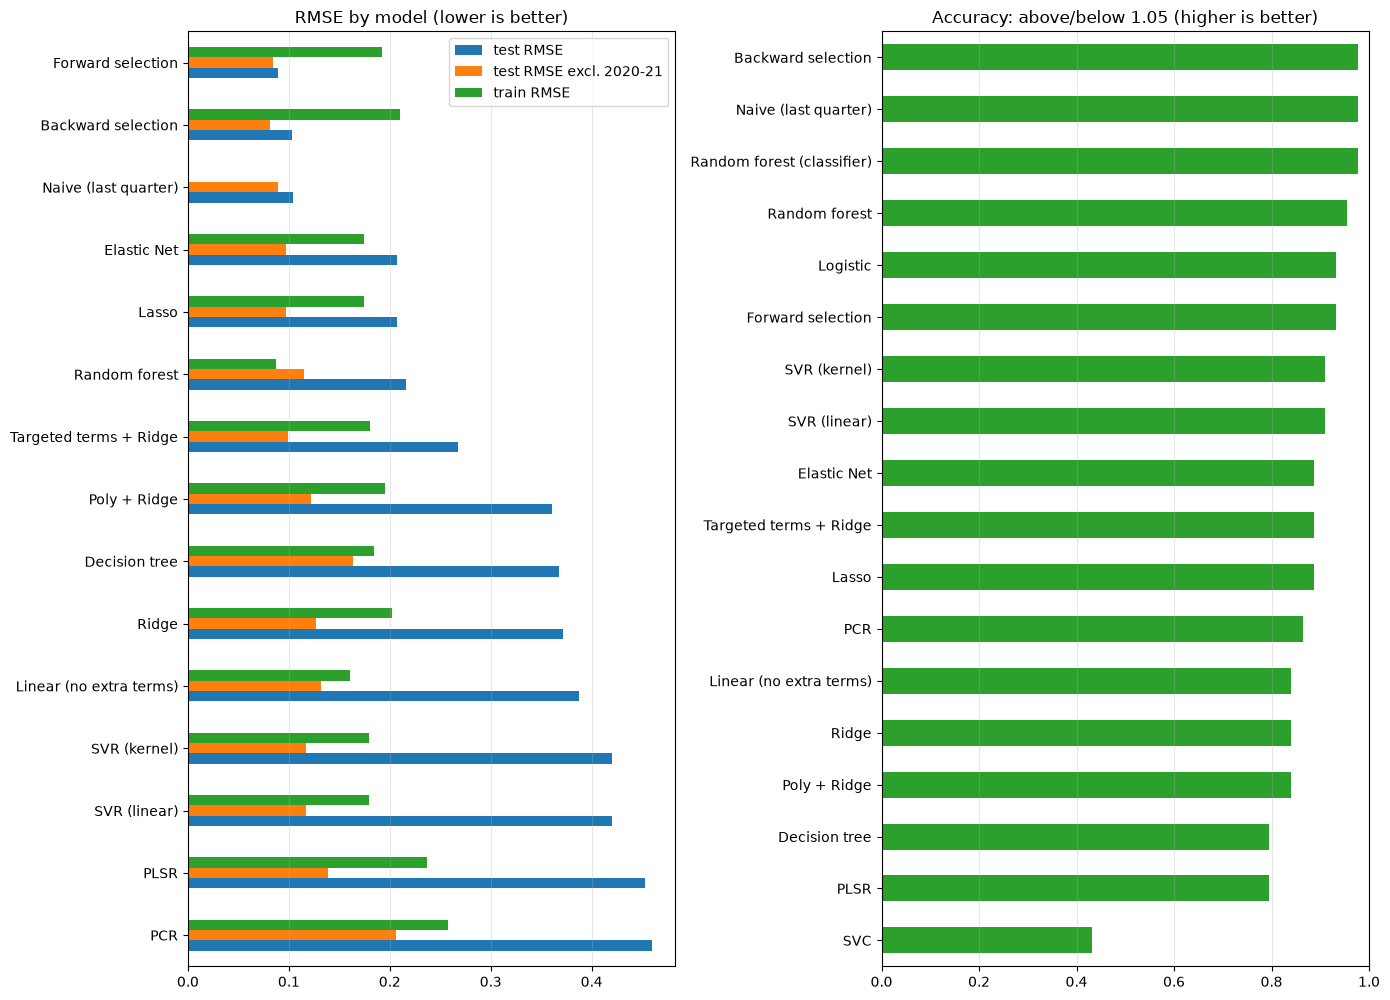

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),Accuracy (vs threshold),CV score,CV metric,best params,saved,test ROC_AUC
Forward selection,regressor,0.089,0.065,0.878,0.659,0.084,0.192,-0.103,0.931818,0.22666,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17,NaN
Backward selection,regressor,0.103,0.063,0.836,0.636,0.081,0.21,-0.107,0.977273,0.235818,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17,NaN
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,0.977273,NaN,NaN,NaN,NaN,NaN
Elastic Net,regressor,0.207,0.114,0.34,0.636,0.097,0.174,0.033,0.886364,0.336756,root_mean_squared_error,"{'elasticnet__alpha': 0.019573417814876617, 'e...",2026-10-18 02:11,NaN
Lasso,regressor,0.207,0.114,0.339,0.636,0.097,0.174,0.033,0.886364,0.336352,root_mean_squared_error,{'lasso__alpha': 0.020309176209047347},2026-10-18 02:06,NaN
Random forest,regressor,0.216,0.125,0.278,0.545,0.115,0.087,0.129,0.954545,0.462389,root_mean_squared_error,"{'randomforestregressor__n_estimators': 200, '...",2026-10-18 05:12,NaN
Targeted terms + Ridge,regressor,0.268,0.139,-0.109,0.614,0.099,0.18,0.088,0.886364,0.353107,root_mean_squared_error,"{'addterms__pairs': (('dq_other_cons_L1', 'une...",2026-10-18 01:43,NaN
Poly + Ridge,regressor,0.361,0.157,-1.014,0.636,0.122,0.195,0.166,0.840909,0.38412,root_mean_squared_error,"{'polynomialfeatures__degree': 1, 'polynomialf...",2026-10-18 01:10,NaN
Decision tree,regressor,0.368,0.178,-1.094,0.5,0.164,0.184,0.184,0.795455,0.464789,root_mean_squared_error,"{'decisiontreeregressor__max_depth': 4, 'decis...",2026-10-18 05:06,NaN
Ridge,regressor,0.372,0.169,-1.138,0.614,0.127,0.202,0.17,0.840909,0.384148,root_mean_squared_error,{'ridge__alpha': 32.57020655659783},2026-10-18 02:00,NaN


In [13]:
X_train, X_test, y_train, y_test, meta = load_model_data()
y_train_bin, y_test_bin, thr = make_binary_target(y_train, y_test)
compare_table = compare(threshold=thr)      # every model (regressors and classifiers) on the same yes/no accuracy
compare_table

In [14]:
compare_table.to_csv(f"{EXPORT_DIR}/comparisons_m1.csv")

In [11]:
# ranking table with the columns that matter most for choosing a model
reg = final[final["type"].isin(["regressor","classifier", "baseline"])].copy()
cols = ["test RMSE", "test RMSE excl. 2020-21", "test MAE", "test DirAcc", "train RMSE", "overfit gap (test - train RMSE)"]
reg[cols] = reg[cols].astype(float)
reg["beats naive (test RMSE)"] = reg["test RMSE"] < float(reg.loc["Naive (last quarter)", "test RMSE"])
reg["beats naive (excl. 2020-21)"] = reg["test RMSE excl. 2020-21"] < float(reg.loc["Naive (last quarter)", "test RMSE excl. 2020-21"])
reg[cols + ["beats naive (test RMSE)", "beats naive (excl. 2020-21)"]].sort_values("test RMSE excl. 2020-21").round(3)

,test RMSE,test RMSE excl. 2020-21,test MAE,test DirAcc,train RMSE,overfit gap (test - train RMSE),beats naive (test RMSE),beats naive (excl. 2020-21)
Backward selection,0.103,0.081,0.063,0.636,0.210,-0.107,True,True
Forward selection,0.089,0.084,0.065,0.659,0.192,-0.103,True,True
Naive (last quarter),0.104,0.089,0.066,NaN,NaN,NaN,False,False
Elastic Net,0.207,0.097,0.114,0.636,0.174,0.033,False,False
Lasso,0.207,0.097,0.114,0.636,0.174,0.033,False,False
Targeted terms + Ridge,0.268,0.099,0.139,0.614,0.180,0.088,False,False
Random forest,0.216,0.115,0.125,0.545,0.087,0.129,False,False
SVR (kernel),0.420,0.117,0.179,0.432,0.179,0.241,False,False
SVR (linear),0.420,0.117,0.179,0.432,0.179,0.241,False,False
Poly + Ridge,0.361,0.122,0.157,0.636,0.195,0.166,False,False


best four (excl. 2020-21): ['Backward selection', 'Forward selection', 'Elastic Net', 'Lasso']


<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

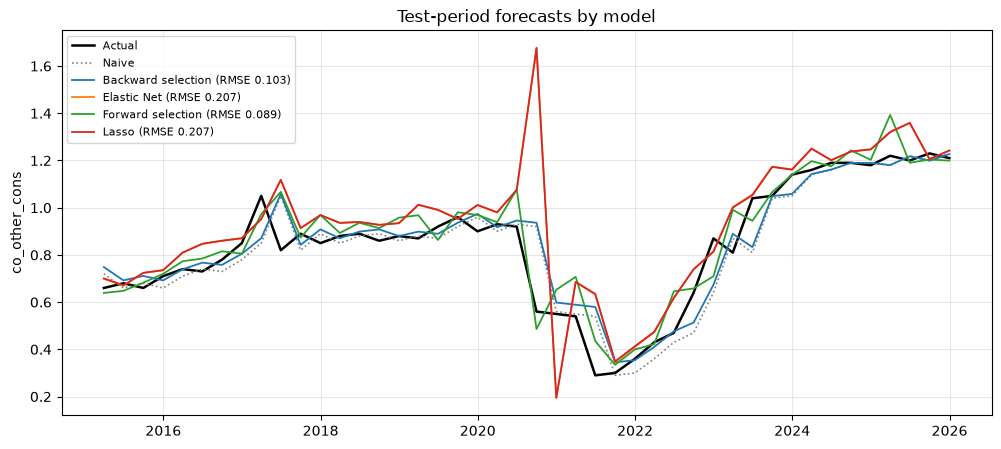

In [8]:
top4 = list(reg.drop(index="Naive (last quarter)").sort_values("test RMSE excl. 2020-21").index[:4])
print("best four (excl. 2020-21):", top4)
plot_forecasts(names=top4)